In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv("smartcart_customers.csv")

In [3]:
data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [4]:
data.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

## 1 Fill Missing Values

In [5]:
data["Income"] = data["Income"].fillna(data["Income"].median())

In [6]:
data.isnull().sum()

ID                     0
Year_Birth             0
Education              0
Marital_Status         0
Income                 0
Kidhome                0
Teenhome               0
Dt_Customer            0
Recency                0
MntWines               0
MntFruits              0
MntMeatProducts        0
MntFishProducts        0
MntSweetProducts       0
MntGoldProds           0
NumDealsPurchases      0
NumWebPurchases        0
NumCatalogPurchases    0
NumStorePurchases      0
NumWebVisitsMonth      0
Complain               0
Response               0
dtype: int64

In [7]:
data["Income"]

0       58138.0
1       46344.0
2       71613.0
3       26646.0
4       58293.0
         ...   
2235    61223.0
2236    64014.0
2237    56981.0
2238    69245.0
2239    52869.0
Name: Income, Length: 2240, dtype: float64

## 2. Feature Engineering

In [8]:
# So we have two date data 
data.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response'],
      dtype='object')

In [9]:
# but Age could be a better or useful attribute so for that we can convert Year_Birth to Age or add a new Column 
data["Age"] = 2026 - data["Year_Birth"]

In [10]:
data["Age"]

0       69
1       72
2       61
3       42
4       45
        ..
2235    59
2236    80
2237    45
2238    70
2239    72
Name: Age, Length: 2240, dtype: int64

In [11]:
data["Dt_Customer"]

0       04-09-2012
1       08-03-2014
2       21-08-2013
3       10-02-2014
4       19-01-2014
           ...    
2235    13-06-2013
2236    10-06-2014
2237    25-01-2014
2238    24-01-2014
2239    15-10-2012
Name: Dt_Customer, Length: 2240, dtype: object

In [12]:
# we also have Dt_customer date of customers joining but generally clustering algorithm are not perform good with dates so for that we can conert them into days like 300 days , etc

# But by defsult pandas follow date pattern like "months-days-year" but in dataset we have "days-months-year"

 # so for that we have to tell that follow dayfirst = True pattern

data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"],dayfirst = True)

max_date = data["Dt_Customer"].max()

data["Customer_Tenure"] = (max_date - data["Dt_Customer"]).dt.days

In [20]:
data["Dt_Customer"]

0      2012-09-04
1      2014-03-08
2      2013-08-21
3      2014-02-10
4      2014-01-19
          ...    
2235   2013-06-13
2236   2014-06-10
2237   2014-01-25
2238   2014-01-24
2239   2012-10-15
Name: Dt_Customer, Length: 2240, dtype: datetime64[ns]

In [21]:
data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,88,3,8,10,4,7,0,1,69,663
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,6,2,1,1,2,5,0,0,72,113
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,42,1,8,2,10,4,0,0,61,312
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,5,2,2,0,4,6,0,0,42,139
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,15,5,5,3,6,5,0,0,45,161


## 3. Add some useful feature by combining existing features

In [22]:
data.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure'],
      dtype='object')

In [23]:
# Add all spending amount by customers
data["Total_Spending"] = data["MntWines"] + data["MntFruits"] + data["MntMeatProducts"] + data["MntFishProducts"] + data["MntSweetProducts"] + data["MntGoldProds"]

In [24]:
data["Family_Members"] = data["Kidhome"] + data["Teenhome"]

In [25]:
data["Education"].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [26]:
# Now replace some features 
data["Education"] = data["Education"].replace({
    "Basic" : "UnderGraduate", "2n Cycle" : "UnderGraduate",
    "Graduation" : "Graduate",
    "Master" : "PostGraduate", "PhD" : "PostGraduate"

})

In [27]:
data["Living_With"] = data["Marital_Status"].replace({
    "Married" : "Partner", "Together" : "Partner",
    "Single" : "Alone", "Divorced" : "Alone", "Absurd" : "Alone","YOLO" : "Alone"

})

In [28]:
data["Living_With"].value_counts()

Living_With
Partner    1444
Alone       719
Widow        77
Name: count, dtype: int64

## 4. Drop some unuseful Columns

In [29]:
data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure,Total_Spending,Family_Members,Living_With
0,5524,1957,Graduate,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1617,0,Alone
1,2174,1954,Graduate,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,27,2,Alone
2,4141,1965,Graduate,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,776,0,Partner
3,6182,1984,Graduate,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,53,1,Partner
4,5324,1981,PostGraduate,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,422,1,Partner


In [30]:
drop_cols = ["ID","Year_Birth","Kidhome","Teenhome","Dt_Customer","Marital_Status"]
drop_spending_cols = ["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]

In [31]:
data.columns


Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response', 'Age', 'Customer_Tenure', 'Total_Spending',
       'Family_Members', 'Living_With'],
      dtype='object')

In [32]:
cols_spending = drop_cols + drop_spending_cols

cleaned_data = data.drop(columns = cols_spending)

In [33]:
cleaned_data.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure,Total_Spending,Family_Members,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,PostGraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


In [34]:
cleaned_data.shape

(2240, 15)

## 5. Detect Outliers 

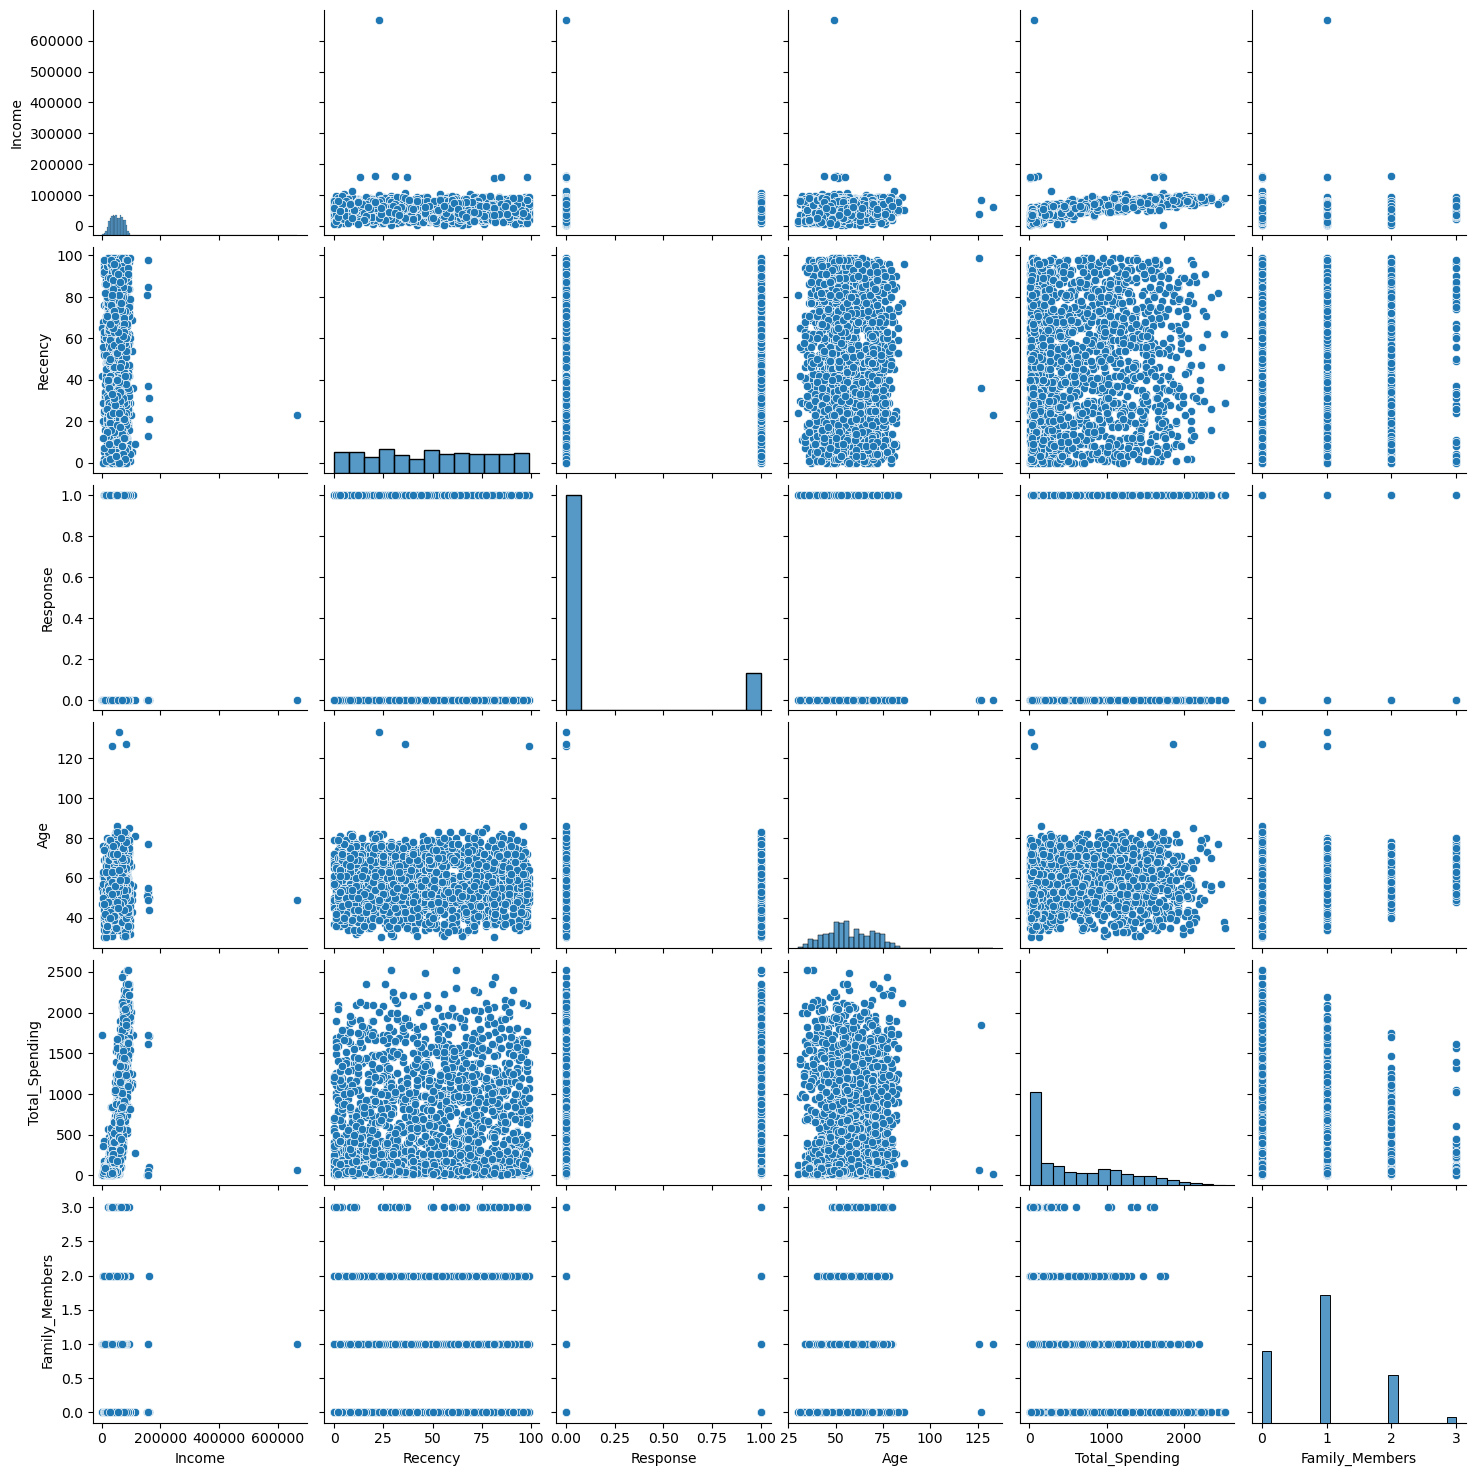

In [35]:
cols = ["Income", "Recency","Response", "Age","Total_Spending","Family_Members"]
# This is for see the some outliers
sns.pairplot(cleaned_data[cols]) # It pair like Income with Income then Income with Recency, Income with Response and so on  

In [36]:
# Remove Outliers

print("Before removing outliers : ",len(cleaned_data))

cleaned_data = cleaned_data[cleaned_data["Age"] < 90]
cleaned_data = cleaned_data[cleaned_data["Income"] < 600000]

print("After removing outliers : ", len(cleaned_data))

Before removing outliers :  2240
After removing outliers :  2236


## 6. HeatMap

In [38]:
# Co-relation matrix
cor = cleaned_data.corr(numeric_only = True)

In [39]:
cor

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure,Total_Spending,Family_Members
Income,1.000000,0.007829,-0.107169,0.450584,0.693781,0.628075,-0.646382,-0.027871,0.161121,0.198835,-0.023677,0.789375,-0.340550
Recency,0.007829,1.000000,-0.000638,-0.010776,0.025226,0.000771,-0.021850,0.005361,-0.198781,0.019396,0.024238,0.020842,0.017826
NumDealsPurchases,-0.107169,-0.000638,1.000000,0.233971,-0.008510,0.068418,0.347216,0.003636,0.002017,0.068286,0.218009,-0.064831,0.439682
NumWebPurchases,0.450584,-0.010776,0.233971,1.000000,0.378049,0.502227,-0.056204,-0.013250,0.148390,0.153873,0.191211,0.519948,-0.146429
NumCatalogPurchases,0.693781,0.025226,-0.008510,0.378049,1.000000,0.518788,-0.520376,-0.018304,0.220813,0.125285,0.095836,0.778343,-0.439631
NumStorePurchases,0.628075,0.000771,0.068418,0.502227,0.518788,1.000000,-0.429857,-0.011563,0.038702,0.139237,0.109727,0.675460,-0.321729
NumWebVisitsMonth,-0.646382,-0.021850,0.347216,-0.056204,-0.520376,-0.429857,1.000000,0.020796,-0.004397,-0.117498,0.272105,-0.499909,0.417908
Complain,-0.027871,0.005361,0.003636,-0.013250,-0.018304,-0.011563,0.020796,1.000000,0.000167,0.004450,0.035685,-0.033784,0.031480
Response,0.161121,-0.198781,0.002017,0.148390,0.220813,0.038702,-0.004397,0.000167,1.000000,-0.018557,0.194232,0.265615,-0.169451
Age,0.198835,0.019396,0.068286,0.153873,0.125285,0.139237,-0.117498,0.004450,-0.018557,1.000000,-0.016451,0.113618,0.095512


<Axes: >

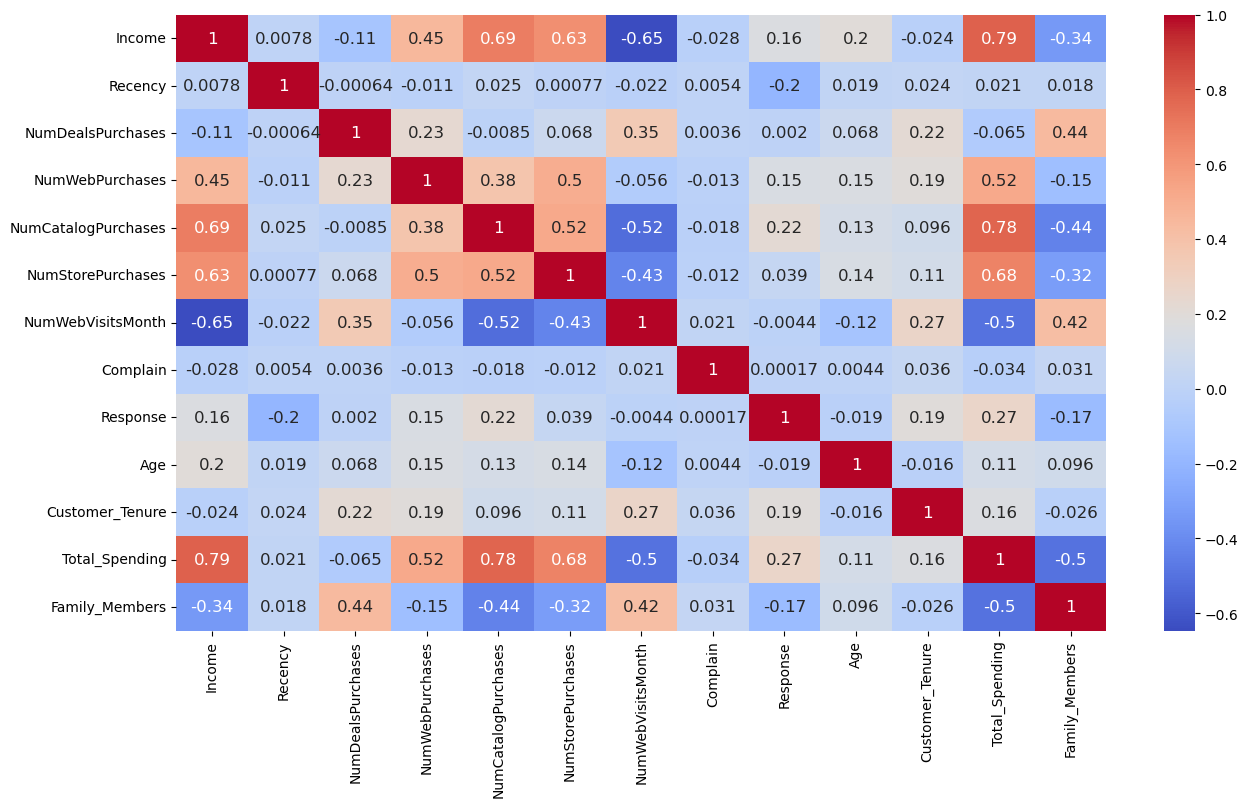

In [42]:
plt.figure(figsize = (15,8))

# Heat map where is high relation it show red box and where is no relation it show blue 
sns.heatmap(
    cor,
    annot= True,
    annot_kws = {"size" : 12},
    cmap = "coolwarm"
)

## 7. Feature Encoding

In [43]:
from sklearn.preprocessing import OneHotEncoder

In [44]:
cleaned_data.head()

,Education,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure,Total_Spending,Family_Members,Living_With
0,Graduate,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,Alone
1,Graduate,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,Alone
2,Graduate,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,Partner
3,Graduate,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,Partner
4,PostGraduate,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,Partner


In [45]:
 cleaned_data["Living_With"]= cleaned_data["Living_With"].replace({
    "Widow" : "Alone"
 })

In [46]:

cols_encode = ["Education" , "Living_With"]
ohe = OneHotEncoder()
encoded_col = ohe.fit_transform(cleaned_data[cols_encode])



In [47]:
encoded_data = pd.DataFrame(
    encoded_col.toarray(),
    columns = ohe.get_feature_names_out(cols_encode),
    index = cleaned_data.index
)

In [48]:
encoded_data.head()

,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Living_With_Alone,Living_With_Partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [49]:
cleaned_data_encoded = pd.concat([cleaned_data.drop(columns = cols_encode), encoded_data], axis =1)

In [50]:
cleaned_data_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure,Total_Spending,Family_Members,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


In [51]:
cleaned_data_encoded.shape

(2236, 18)

In [52]:
# cleaned_data["Living_With"].value_counts()
cleaned_data_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure,Total_Spending,Family_Members,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0


## 8. Scalling data

In [53]:
from sklearn.preprocessing import StandardScaler

In [54]:
X = cleaned_data_encoded

In [55]:
ss = StandardScaler()
X_scaled = ss.fit_transform(X)

In [56]:
X_scaled

array([[ 0.28894655,  0.30685572,  0.34873831, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [-0.262003  , -0.38397129, -0.16869955, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [ 0.91842301, -0.7984675 , -0.68613742, ..., -0.35877969,
        -0.74204052,  0.74204052],
       ...,
       [ 0.234898  ,  1.44672029, -0.68613742, ..., -0.35877969,
         1.3476353 , -1.3476353 ],
       [ 0.80780332, -1.42021181, -0.16869955, ..., -0.35877969,
        -0.74204052,  0.74204052],
       [ 0.04280841, -0.31488859,  0.34873831, ..., -0.35877969,
        -0.74204052,  0.74204052]])

## 9. Visualizationof Data

In [57]:
# we can visualize 2D so we need to reduce the dimention or feature so we can visualize it 
from sklearn.decomposition import PCA

In [58]:
pca = PCA(n_components = 2)
X_pca = pca.fit_transform(X_scaled)


In [59]:
# to check how much it is capture the information after pca
pca.explained_variance_ratio_ # araound 0.23 + 0.11 = 0.34 which is 34% data is captured or covered after  so we can add some more features

array([0.23163158, 0.11385454])

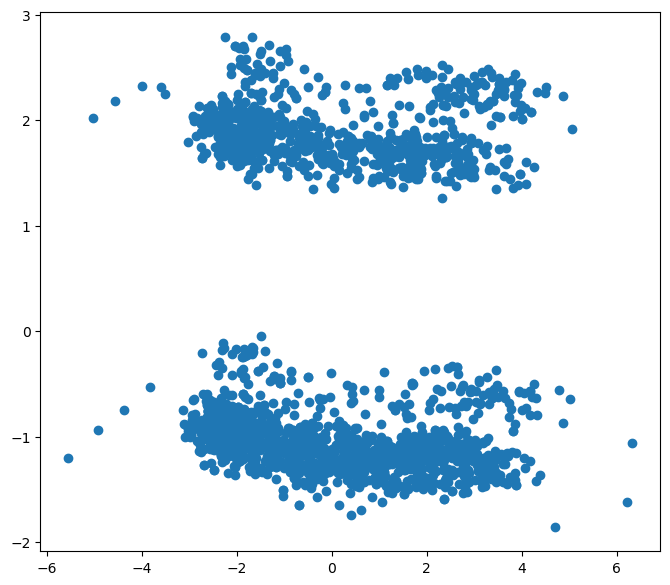

In [60]:
plt.figure(figsize= (8,7))
plt.scatter(X_pca[:,0], X_pca[:,1])

In [61]:
 # now print 3D plot 

pca = PCA(n_components = 3)
X_pca = pca.fit_transform(X_scaled)

In [62]:
pca.explained_variance_ratio_ # now we have 0.23 + 0.11 + 0.10 = 44 which is not good but better then previous 

array([0.23163158, 0.11385454, 0.10405815])

Text(0.5, 0.92, '3D Projection')

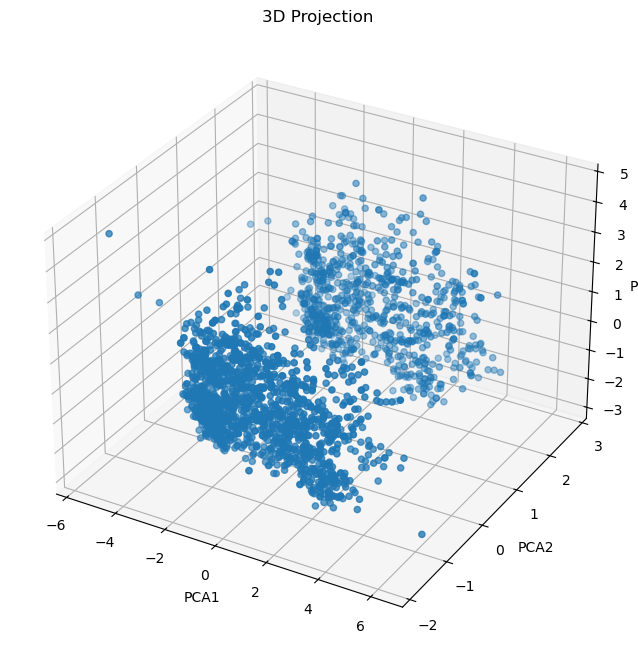

In [63]:
# To print 3D plot
fig = plt.figure(figsize= (8,8))
ax = fig.add_subplot(111, projection = "3d")
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2])

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D Projection")

## 10. Identify K value

## Elbow Method

In [64]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

In [65]:
wcss =[]

for k in range(1, 11):
    kmean = KMeans(n_clusters = k, random_state = 42)
    kmean.fit_predict(X_pca)
    wcss.append(kmean.inertia_)
    

D:\Users\Ujjwal singh\AnacondaFiles\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\Users\Ujjwal singh\AnacondaFiles\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "D:\Users\Ujjwal singh\AnacondaFiles\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "D:\Users\Ujjwal singh\AnacondaFiles\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fd

In [66]:
knee = KneeLocator(range(1, 11), wcss, curve = "convex", direction = "decreasing")

optional_k = knee.elbow

In [67]:
optional_k

np.int64(4)

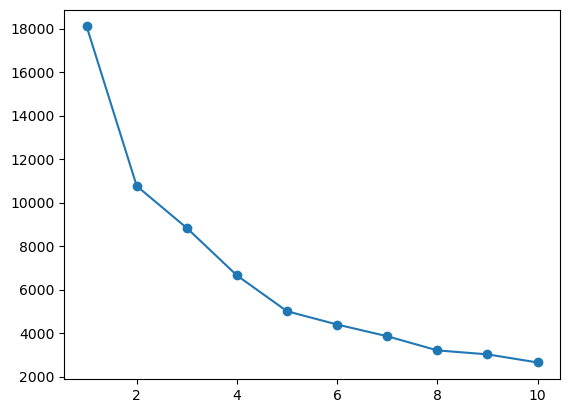

In [68]:
plt.plot(range(1,11), wcss, marker = "o")

## Silhouette score

In [69]:
from sklearn.metrics import silhouette_score

In [70]:
scores = []

for k in range(2,11):
    kmean = KMeans(n_clusters = k, random_state = 42)
    labels = kmean.fit_predict(X_pca)
    score = silhouette_score(X_pca, labels)
    scores.append(score)

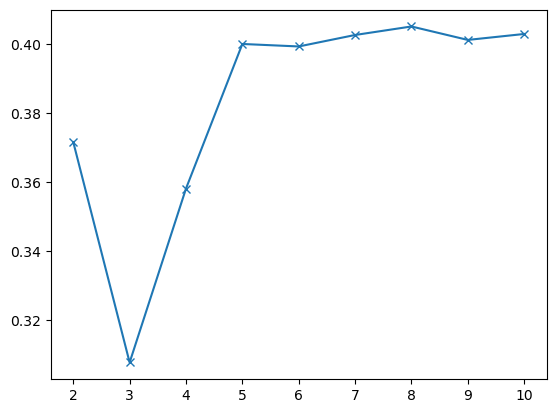

In [71]:
plt.plot(range(2,11), scores, marker= "x")


# 11. Clustering

## i) KMean Clustering

In [72]:
# For Kmean
kmean = KMeans(n_clusters = 4, random_state =42)
labels_kmean = kmean.fit_predict(X_pca)

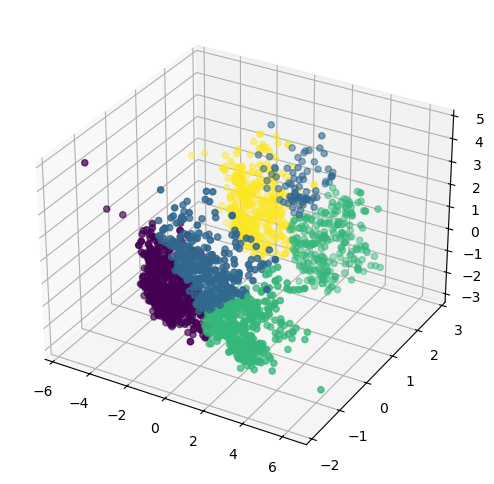

In [75]:
fig =plt.figure(figsize= (6,7))
axis = fig.add_subplot(111, projection = "3d")
axis.scatter(X_pca[:,0],X_pca[:,1], X_pca[:,2] , c = labels_kmean)

In [77]:
from sklearn.cluster import AgglomerativeClustering

In [78]:
agg_cls = AgglomerativeClustering(n_clusters = 4, linkage = "ward")
labels_agg = agg_cls.fit_predict(X_pca)

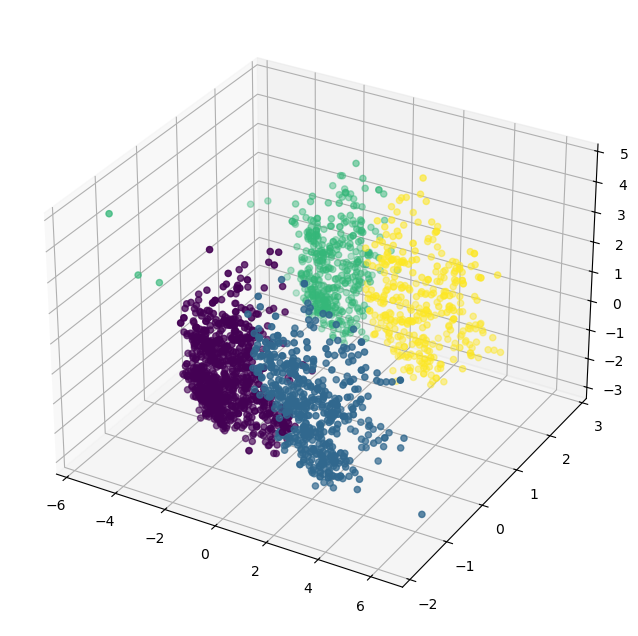

In [81]:
fig = plt.figure(figsize = (8,8))
ax = fig.add_subplot(111, projection = "3d")
ax.scatter(X_pca[:,0], X_pca[:,1], X_pca[:,2], c = labels_agg)

In [91]:
X["Labels"] = labels_agg

In [92]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure,Total_Spending,Family_Members,Education_Graduate,Education_PostGraduate,Education_UnderGraduate,Living_With_Alone,Living_With_Partner,Labels
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,3
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,1
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0


## 11. Characterization of clusters

<Axes: xlabel='Labels', ylabel='count'>

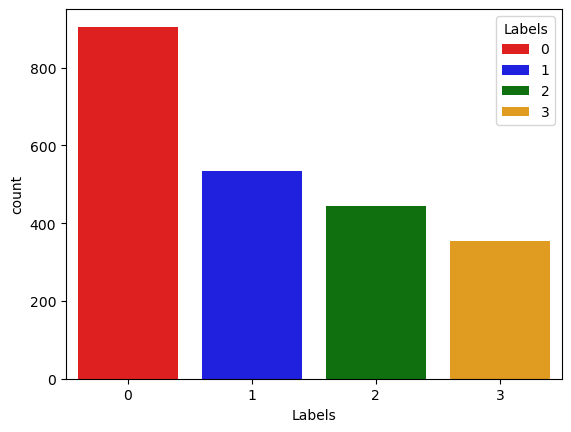

In [96]:
col = ["red", "blue", "green","orange"]

sns.countplot(x = X["Labels"], palette = col, hue = X["Labels"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

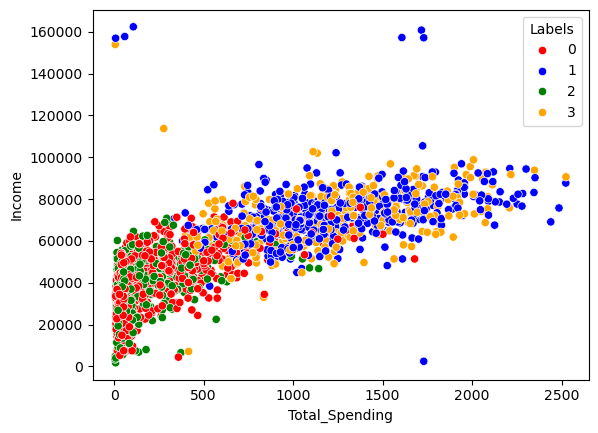

In [97]:
# Visualize the behaviour through the scatter plot

# here we analyze four types of customer behaviour 
sns.scatterplot(x = X["Total_Spending"], y = X["Income"], hue = X["Labels"], palette = col)

## 12. Final Result analyze the table to understand the behaviour of 4 type of customers

In [98]:
# Clusters summary  to analyze the four customers behaviour by numbers 

# This is the final result where we can analyze each customer behaviour by comparing each cluster to each other 
cluster_summary = X.groupby("Labels").mean()
print(cluster_summary)

              Income    Recency  NumDealsPurchases  NumWebPurchases  \
Labels                                                                
0       39680.580110  48.914917           2.594475         3.153591   
1       72808.445693  49.202247           1.958801         5.687266   
2       36960.143018  48.319820           2.594595         2.713964   
3       70722.681303  50.504249           1.855524         5.790368   

        NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
Labels                                                                        
0                  0.969061           4.143646           6.307182  0.011050   
1                  5.498127           8.659176           3.580524  0.005618   
2                  0.837838           3.623874           6.659910  0.011261   
3                  5.014164           8.430595           3.728045  0.005666   

        Response        Age  Customer_Tenure  Total_Spending  Family_Members  \
Labels            